# Makale Yeniden Üretimi · Bölüm 6: Doğrusal Regresyon

**Ahmet Batuhan Kaya · 20269348005**

**Makale:** Hastie, T., Tibshirani, R. ve Tibshirani, R. J. (2020). *Best Subset, Forward Stepwise or Lasso? Analysis and Recommendations Based on Extensive Comparisons.* Statistical Science, 35(4), 579–592.

**Bölümle bağlantısı:** Molnar'ın 6. bölümü, çok sayıda öznitelik olduğunda doğrusal modeli yorumlanabilir tutmak için **seyrek doğrusal modelleri** önerir: lasso, ileri adımsal seçim, geri adımsal seçim. Makale tam olarak bu yöntemleri (ve en iyi alt küme seçimini) geniş bir simülasyonla karşılaştırır.

**Bu defterde:**

1. Makalenin simülasyonunu Python ile yeniden üretiyoruz (düşük ve orta boyutlu ayarlar).
2. Makalenin üç ana iddiasını kendi sonuçlarımızla sınıyoruz.
3. **Uzantı:** Kitabın bisiklet verisine 20 sahte öznitelik ekleyip hangi yöntemin "yalan söylediğine" bakıyoruz.

**Çalıştırma:** `pip install numpy pandas scikit-learn abess pyreadr matplotlib joblib`. Tam simülasyon iki çekirdekte yaklaşık 11 dakika sürer; bu yüzden varsayılan olarak `sonuclar/` klasöründeki hazır sonuçlar okunur. Baştan üretmek için aşağıdaki `YENIDEN_CALISTIR` değerini `True` yapın.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display

import secim, bisiklet, figurler

YENIDEN_CALISTIR = False   # True: tüm simülasyonu baştan çalıştırır (~11 dk)
print("SNR değerleri:", np.round(secim.SNR_DEGERLERI, 2))

SNR değerleri: [0.05 0.09 0.14 0.25 0.42 0.71 1.22 2.07 3.52 6.  ]


## 1. Simülasyon düzeni (makaledeki gibi)

| Öğe | Değer |
|---|---|
| Ayarlar | **düşük**: n=100, p=10, s=5 · **orta**: n=500, p=100, s=5 |
| Öznitelikler | $x \sim N_p(0, \Sigma)$, $\Sigma_{ij} = \rho^{|i-j|}$, $\rho \in \{0;\ 0{,}35;\ 0{,}7\}$ |
| Gerçek katsayılar | β tipi 1, 2, 3, 5 (aşağıda) |
| Gürültü | $\sigma^2 = \beta_0^T \Sigma \beta_0 / \text{SNR}$, SNR: 0,05 ile 6 arasında log ölçekte 10 değer |
| Ayarlama | Her yöntem, eğitimle aynı boyutta ayrı bir **doğrulama kümesinde** ayarlanır |
| Tekrar | Her senaryo için 20 (Şekil 1-2'deki odak senaryo için 100) |

**Ölçüler** (gerçek $\Sigma$ ile hesaplanır):

- Göreli risk: $RR(\hat\beta) = \dfrac{(\hat\beta-\beta_0)^T\Sigma(\hat\beta-\beta_0)}{\beta_0^T\Sigma\beta_0}$
- Göreli test hatası: $RTE(\hat\beta) = \dfrac{(\hat\beta-\beta_0)^T\Sigma(\hat\beta-\beta_0)+\sigma^2}{\sigma^2}$ (mükemmel = 1)
- Açıklanan varyans oranı: $PVE(\hat\beta) = 1-\dfrac{(\hat\beta-\beta_0)^T\Sigma(\hat\beta-\beta_0)+\sigma^2}{\beta_0^T\Sigma\beta_0+\sigma^2}$ (en iyi = SNR/(1+SNR))

In [2]:
for t in [1, 2, 3, 5]:
    print(f"β tipi {t}:", np.round(secim.katsayi(t, 10, 5), 3))

β tipi 1: [1. 0. 1. 0. 1. 0. 0. 1. 0. 1.]
β tipi 2: [1. 1. 1. 1. 1. 0. 0. 0. 0. 0.]
β tipi 3: [10.     7.625  5.25   2.875  0.5    0.     0.     0.     0.     0.   ]
β tipi 5: [1.    1.    1.    1.    1.    0.5   0.25  0.125 0.062 0.031]


## 2. Dört yöntem

| Yöntem | Ne yapar | Ayar parametresi |
|---|---|---|
| **En iyi alt küme** | Her k için eğitim hatasını en aza indiren k değişkenli alt kümeyi bulur | k = 0…10 (düşük), 0…50 (orta) |
| **İleri adımsal** | Her adımda modele en çok katkı yapan değişkeni ekler | adım sayısı |
| **Lasso** | $\min \lVert y-X\beta\rVert^2/(2n) + \lambda\lVert\beta\rVert_1$ | λ (50 / 100 değer) |
| **Gevşetilmiş lasso** | $\hat\beta(\lambda,\gamma)=\gamma\,\hat\beta^{lasso}(\lambda)+(1-\gamma)\,\hat\beta^{EKK}(\lambda)$; EKK lasso'nun seçtiği değişkenlerde | λ ve γ ∈ {1, …, 0} (10 değer) |

**Makaleden farkımız:** Makale en iyi alt kümeyi Gurobi ile (karma tam sayılı optimizasyon) çözer. Düşük ayarda biz **1024 alt kümenin hepsini tarıyoruz**, yani çözüm kesin. Orta ayarda (2¹⁰⁰ alt küme) tam tarama imkânsız; aynı problemi yaklaşık çözen açık kaynaklı **abess** algoritmasını kullanıyoruz. Makale de bu ayarda Gurobi'nin 50 çözümün ancak ~18'inin en iyi olduğunu doğrulayabildiğini belirtiyor.

Tek bir denemenin çıktısı:

In [3]:
pd.DataFrame(secim.tek_deneme("low", rho=0.35, snr=1.22, beta_tipi=2, tohum=7)).round(3)[
    ["yontem", "RR", "RTE", "PVE", "sifirdan_farkli", "dogru_secilen"]]

,yontem,RR,RTE,PVE,sifirdan_farkli,dogru_secilen
0,En iyi alt küme,0.129,1.158,0.479,6,5
1,İleri adımsal,0.129,1.158,0.479,6,5
2,Lasso,0.118,1.144,0.485,8,5
3,Gevşetilmiş lasso,0.068,1.083,0.512,5,5


In [4]:
if YENIDEN_CALISTIR:
    import subprocess, sys
    subprocess.run([sys.executable, "calistir.py"], check=True)        # tam ızgara, ~8 dk
    subprocess.run([sys.executable, "calistir_odak.py"], check=True)   # odak senaryo, ~3 dk
sonuc = pd.read_csv("sonuclar/sonuclar.csv")
odak = pd.read_csv("sonuclar/odak_sonuclar.csv")
print(len(sonuc), "satır (tam ızgara) ·", len(odak), "satır (odak senaryo)")

19200 satır (tam ızgara) · 8000 satır (odak senaryo)


## 3. Sonuçlar ve makalenin iddiaları

### İddia 1: "Ne en iyi alt küme ne de lasso her durumda kazanır. Düşük SNR'de lasso, yüksek SNR'de en iyi alt küme daha iyidir."

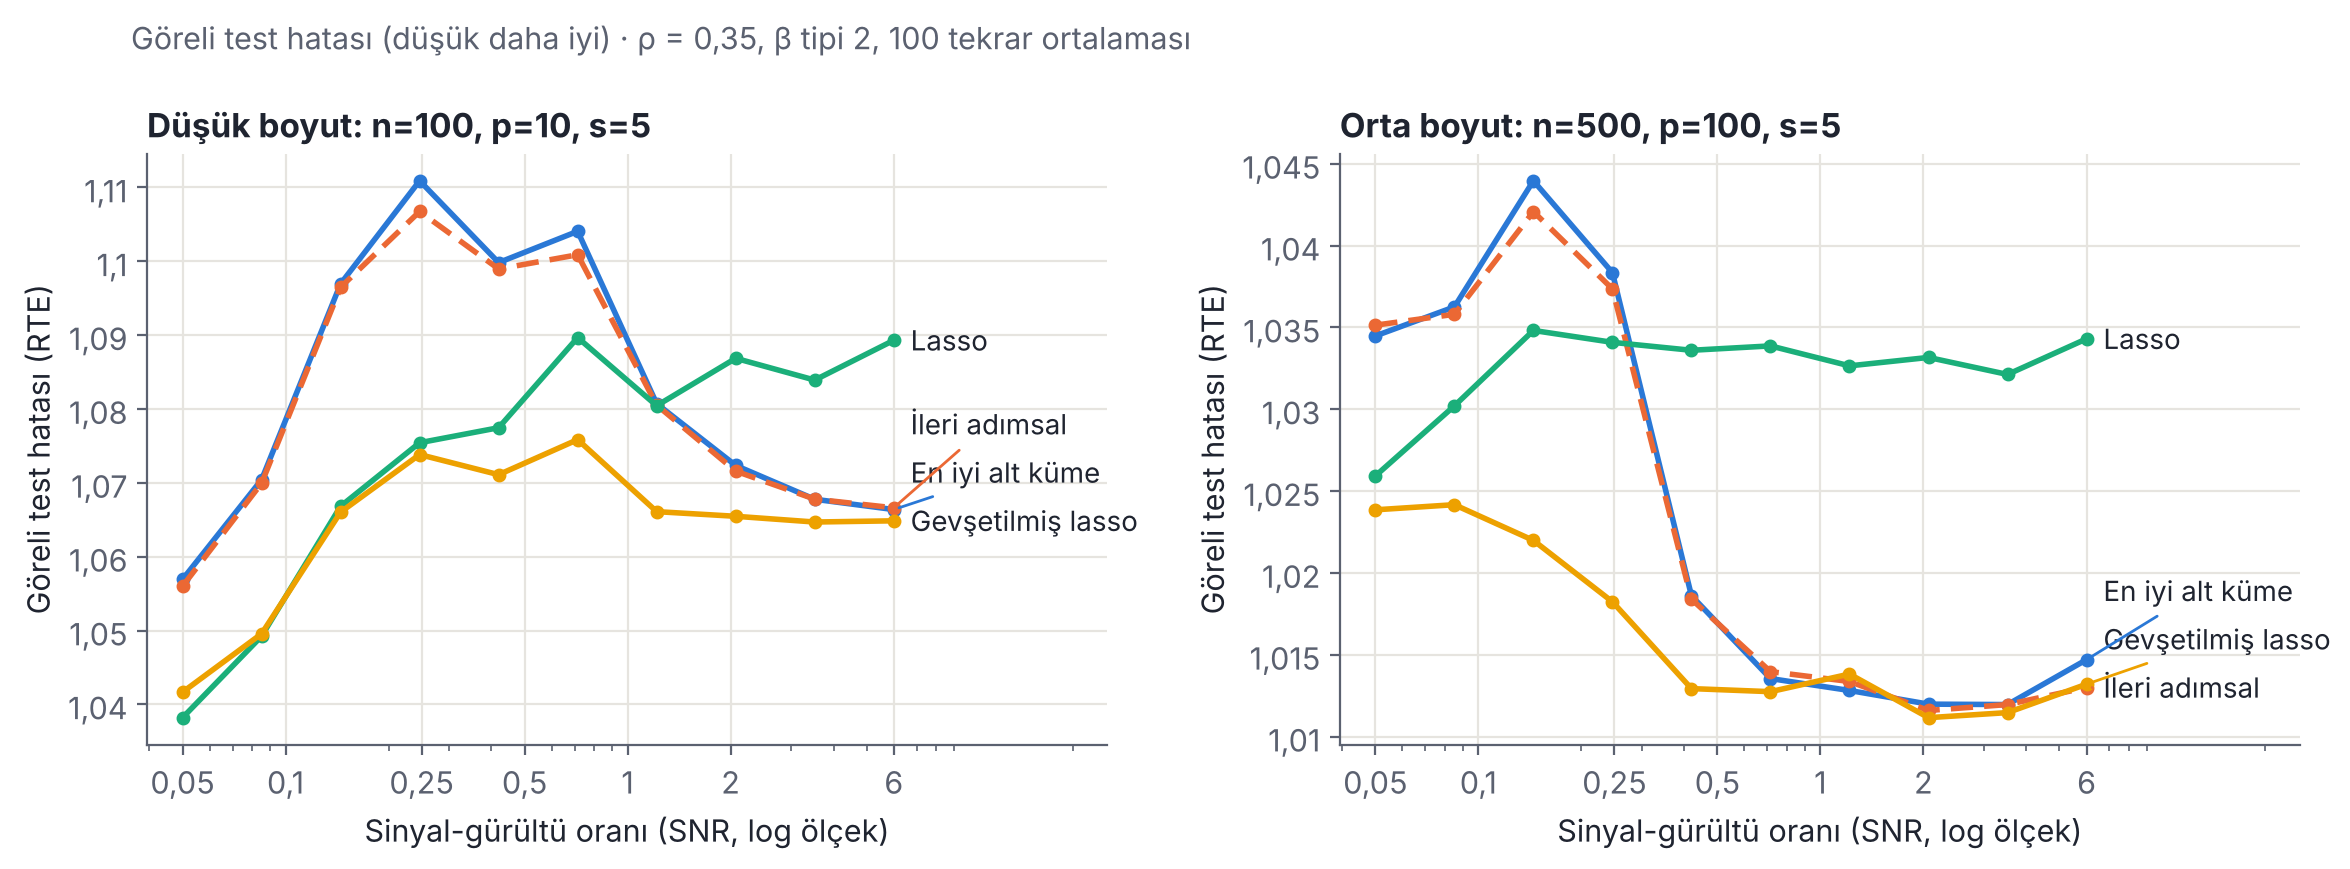

yontem,En iyi alt küme,Gevşetilmiş lasso,Lasso,İleri adımsal
snr,,,,
0.050000,1.057,1.042,1.038,1.056
0.085112,1.070,1.050,1.049,1.070
0.144881,1.097,1.066,1.067,1.096
0.246621,1.111,1.074,1.075,1.107
0.419808,1.100,1.071,1.077,1.099
0.714613,1.104,1.076,1.090,1.101
1.216440,1.081,1.066,1.080,1.081
2.070670,1.072,1.065,1.087,1.072
3.524773,1.068,1.065,1.084,1.068


In [5]:
display(Image("sekiller/sekil1_rte.png", width=900))
t = odak[odak.ayar == "low"].pivot_table(index="snr", columns="yontem", values="RTE").round(3)
t

Düşük ayarda lasso, SNR ≈ 1'e kadar en iyi alt kümeden iyi; sonrasında en iyi alt küme öne geçiyor. Makale bu kesişmeyi **SNR ≈ 1,22** civarında raporluyor; bizim eğrilerimiz de tam bu noktada kesişiyor. Orta ayarda kesişme daha erken, SNR 0,25 ile 0,4 arasında geliyor.

Tek senaryoya bağlı kalmamak için 12 senaryonun (3 ρ × 4 β tipi) hepsine bakalım:

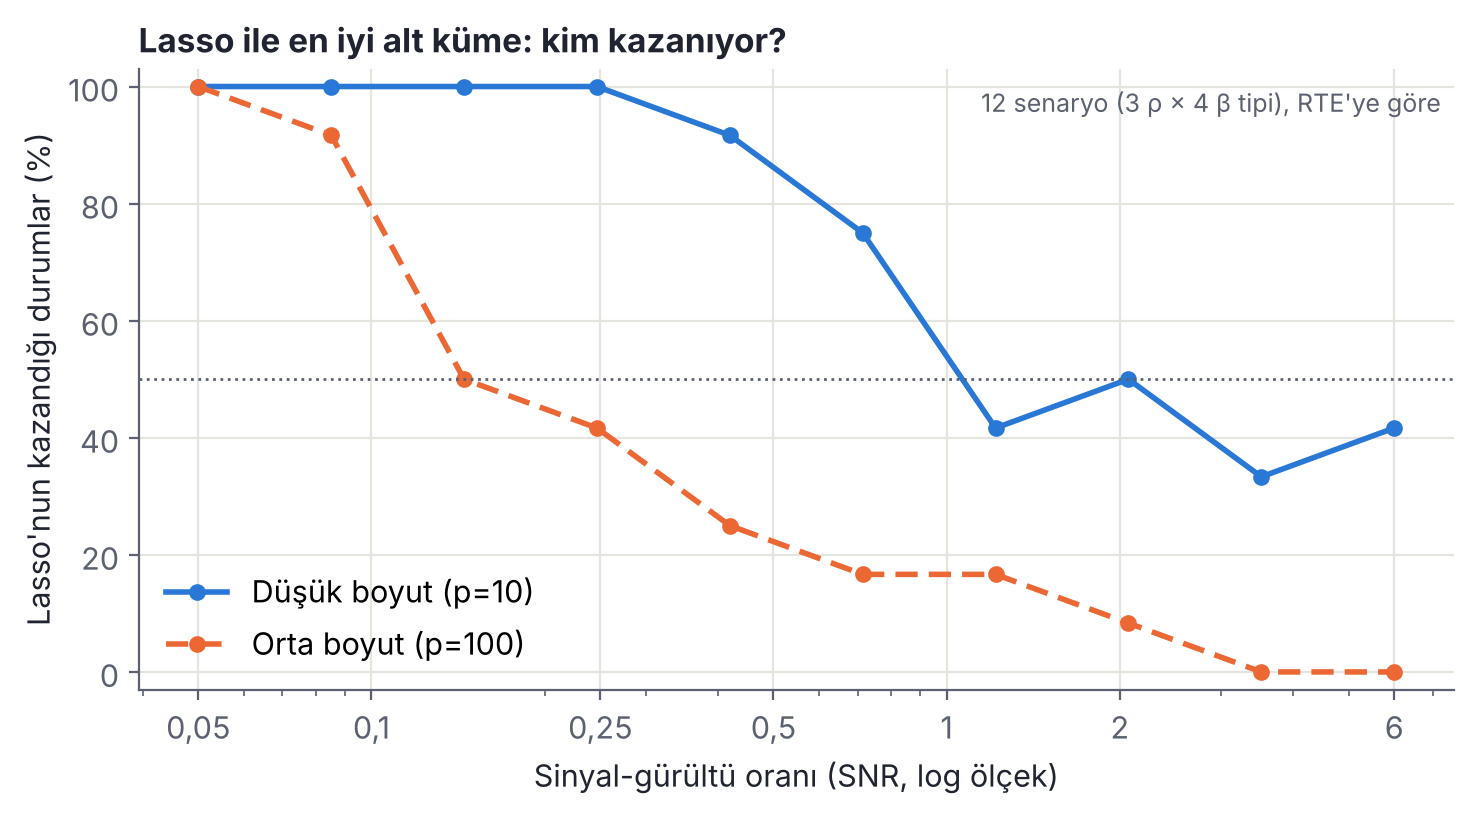

ayar,low,medium
snr,,
0.050000,100.0,100.0
0.085112,100.0,92.0
0.144881,100.0,50.0
0.246621,100.0,42.0
0.419808,92.0,25.0
0.714613,75.0,17.0
1.216440,42.0,17.0
2.070670,50.0,8.0
3.524773,33.0,0.0


In [6]:
display(Image("sekiller/sekil3_kazanan.png", width=650))
g = sonuc.groupby(["ayar", "rho", "beta_tipi", "snr", "yontem"]).RTE.mean().unstack()
(100 * (g["Lasso"] < g["En iyi alt küme"]).groupby(level=["ayar", "snr"]).mean().unstack(0)).round(0)

### İddia 2: "En iyi alt küme ile ileri adımsal seçim neredeyse aynı sonuç verir."

Şekil 1'de mavi ve turuncu kesikli çizgiler neredeyse üst üste. Tüm ızgarada ortalama fark:

In [7]:
fark = (g["En iyi alt küme"] - g["İleri adımsal"]).abs()
print("Ortalama |RTE farkı|:", round(fark.mean(), 4), "· en büyük:", round(fark.max(), 4))

Ortalama |RTE farkı|: 0.0017 · en büyük: 0.0149


### İddia 3: "Gevşetilmiş lasso genel olarak en iyisidir: düşük SNR'de lasso gibi, yüksek SNR'de en iyi alt küme gibi davranır."

In [8]:
en_iyi = g.min(axis=1)
kazanan = g.idxmin(axis=1).groupby(level=0).value_counts().unstack(0).fillna(0).astype(int)
yakin = (g.div(en_iyi, axis=0) <= 1.01).groupby(level=0).mean().T.round(2)
print("En düşük RTE'yi kaç senaryoda aldı (120 senaryo/ayar):"); display(kazanan)
print("En iyiye %1 yakın olduğu senaryoların oranı:"); display(yakin)

En düşük RTE'yi kaç senaryoda aldı (120 senaryo/ayar):


ayar,low,medium
En iyi alt küme,9,29
Gevşetilmiş lasso,72,79
Lasso,37,4
İleri adımsal,2,8


En iyiye %1 yakın olduğu senaryoların oranı:


ayar,low,medium
yontem,,
En iyi alt küme,0.39,0.73
Gevşetilmiş lasso,0.97,1.00
Lasso,0.72,0.34
İleri adımsal,0.37,0.78


### Yorumlanabilirlik açısından: kaç değişken seçiliyor?

Molnar'ın bölümü için asıl önemli olan bu: Lasso, büzülmeyi telafi etmek için **çok daha fazla** değişken seçiyor. Gerçekte 5 değişken önemli; orta ayarda lasso ortalama 12-18 değişken seçiyor. Diğer üç yöntem 5'e yakın kalıyor.

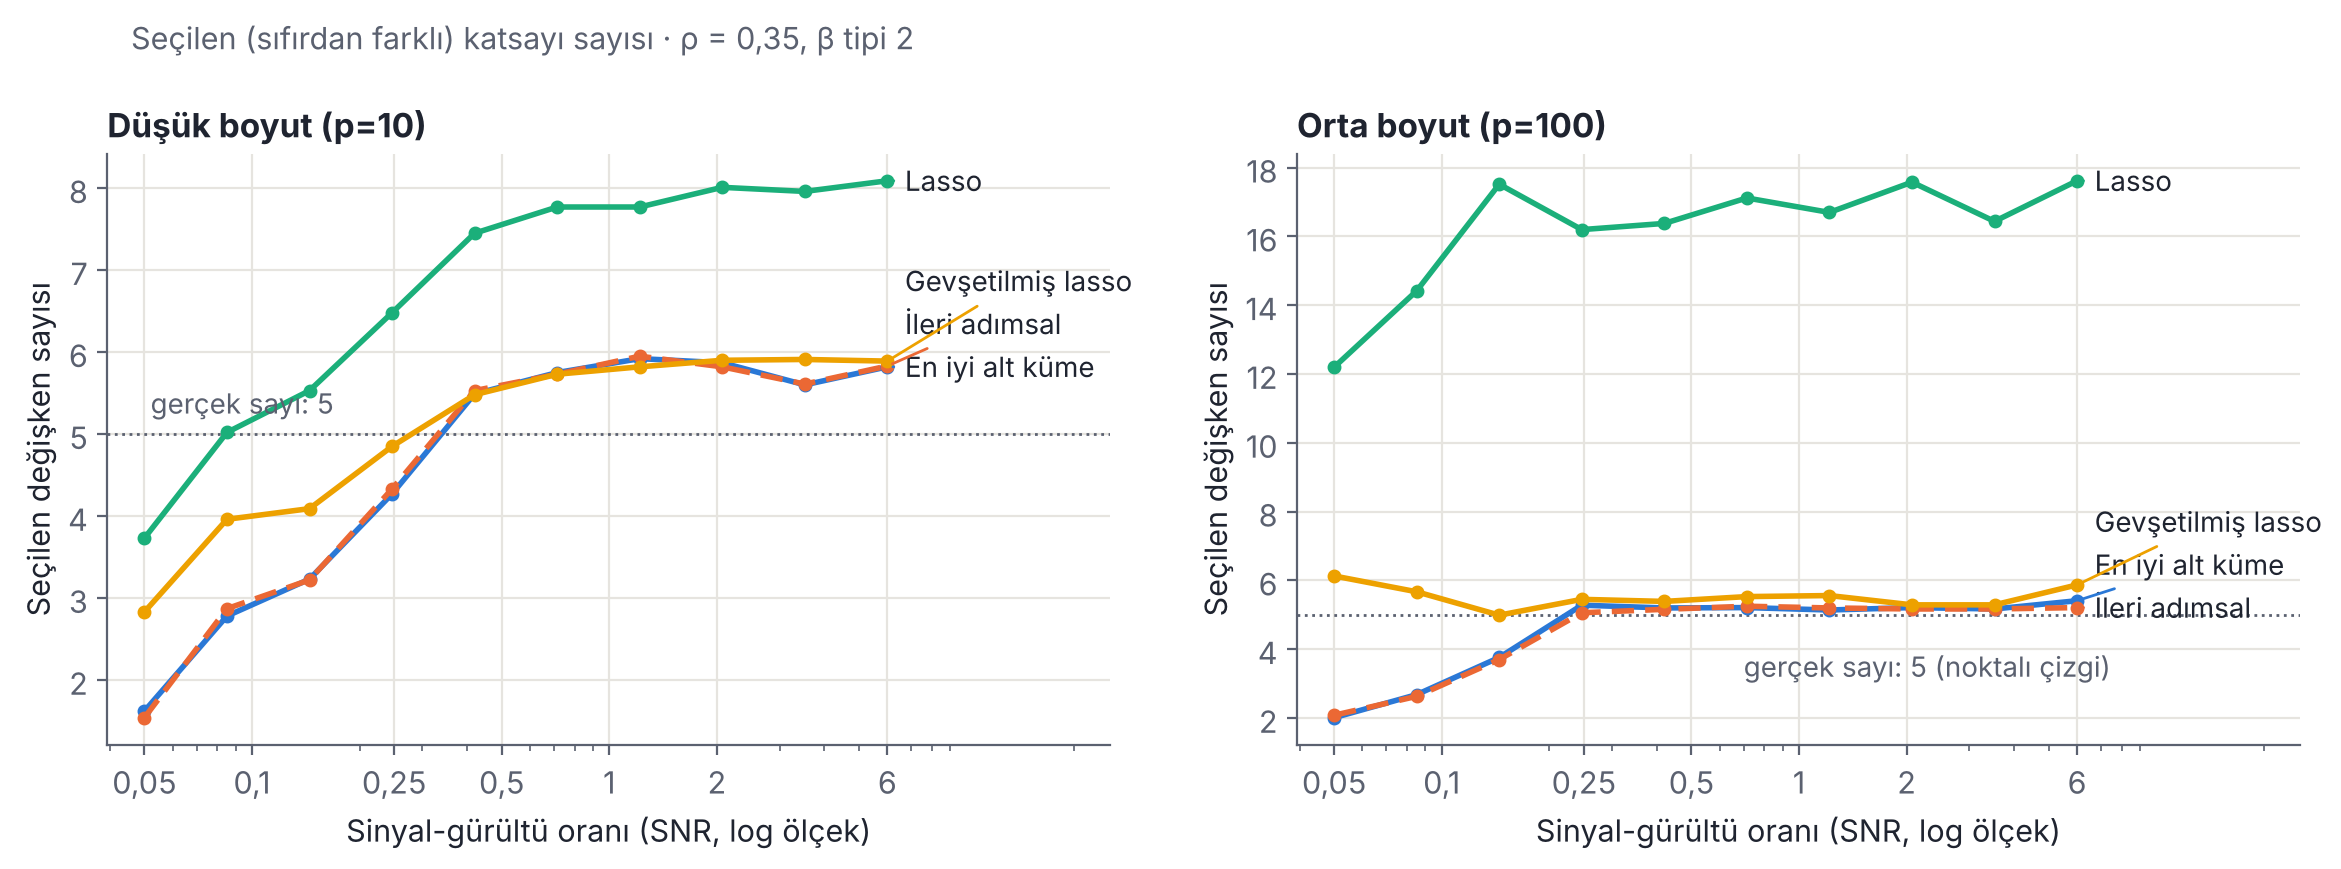

ayar,low,medium
yontem,,
En iyi alt küme,4.6,4.5
Gevşetilmiş lasso,5.0,5.5
Lasso,6.8,16.2
İleri adımsal,4.6,4.5


In [9]:
display(Image("sekiller/sekil2_secilen_sayi.png", width=900))
odak.groupby(["ayar", "yontem"]).sifirdan_farkli.mean().unstack(0).round(1)

Makalenin son gözlemi de bizde tekrar ediyor: PVE farkları mutlak olarak küçük.

In [10]:
sonuc.groupby(["ayar", "yontem"]).PVE.mean().unstack(0).round(3)

ayar,low,medium
yontem,,
En iyi alt küme,0.354,0.385
Gevşetilmiş lasso,0.365,0.390
Lasso,0.363,0.382
İleri adımsal,0.354,0.386


## 4. Uzantı: bisiklet verisi ve 20 sahte öznitelik

Simülasyon "gerçek" katsayıları bildiğimiz için kolay. Gerçek veride hangi değişkenin gerçekten önemli olduğunu bilmeyiz. Bu yüzden şu deneyi kurduk:

- Kitabın 6. bölümündeki bisiklet verisi ve aynı öznitelikler (mevsim, tatil, iş günü, hava, sıcaklık, nem, rüzgâr, gün sayısı).
- Buna hedefle **hiçbir ilişkisi olmayan 20 sahte öznitelik** (rastgele sayı) ekledik.
- 100 rastgele bölme: %50 eğitim, %25 doğrulama, %25 test.

Soru: Hangi yöntem sahte öznitelikleri modele sokuyor? Yani hangi yöntemin **açıklaması** yanıltıcı?

In [11]:
X, y = bisiklet.bisiklet_verisi()
print("Özniteliksiz (yalnız kitap öznitelikleri):")
s0, c0 = bisiklet.bolme_deneyi(X, y, tekrar=100, tohum=0)
display(s0.groupby("yontem")[["RMSE", "sifirdan_farkli"]].mean().round(1))

Xg = bisiklet.gurultu_ekle(X, k=20)
s1, c1 = bisiklet.bolme_deneyi(Xg, y, tekrar=100, tohum=2)
sahte = [c for c in c1.columns if c.startswith("sahte")]
ozet = s1.groupby("yontem")[["RMSE", "sifirdan_farkli"]].mean()
ozet["sahte_secilen"] = c1.assign(n=c1[sahte].sum(axis=1)).groupby("yontem").n.mean()
print("20 sahte öznitelik eklenince:"); display(ozet.round(1))

Özniteliksiz (yalnız kitap öznitelikleri):


,RMSE,sifirdan_farkli
yontem,,
En iyi alt küme,905.1,9.7
Gevşetilmiş lasso,903.9,9.7
Lasso,902.8,10.4
İleri adımsal,906.2,9.6


20 sahte öznitelik eklenince:


,RMSE,sifirdan_farkli,sahte_secilen
yontem,,,
En iyi alt küme,924.8,9.9,1.2
Gevşetilmiş lasso,925.4,10.8,2.0
Lasso,926.6,19.0,9.2
İleri adımsal,926.6,9.9,1.3


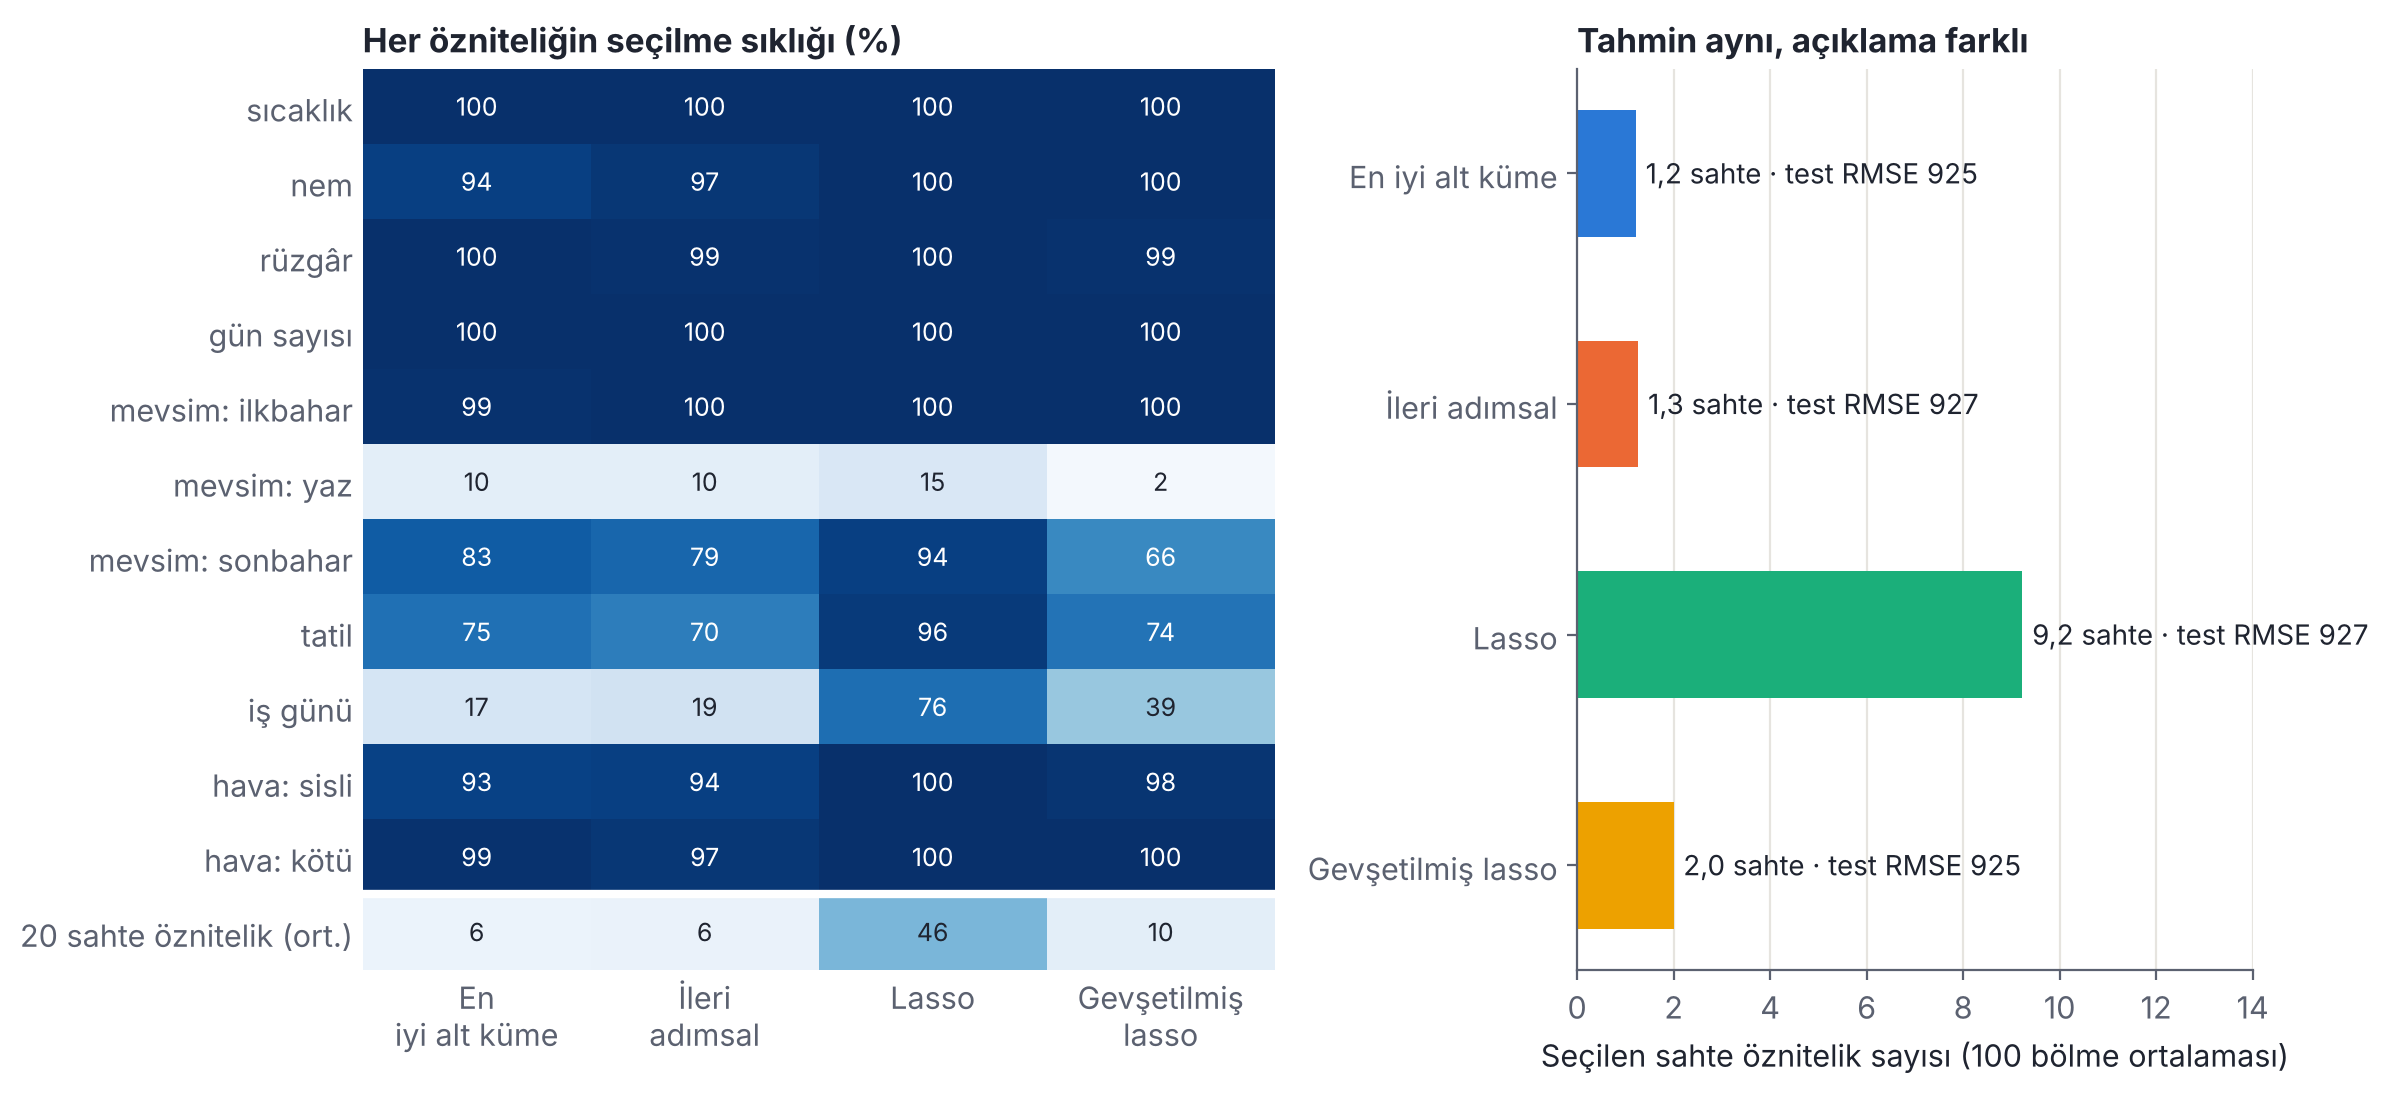

In [12]:
display(Image("sekiller/sekil4_bisiklet.png", width=950))

**Sonuç:** Dört yöntemin test hatası neredeyse aynı (RMSE ≈ 925). Ama lasso, 20 sahte öznitelikten ortalama **9'unu** modele sokuyor. En iyi alt küme ve ileri adımsal ~1, gevşetilmiş lasso ~2 sahte öznitelik seçiyor.

Bu, Molnar'ın kitabındaki bir uyarının somut hali: Tahmin performansı aynı olan iki model çok farklı **açıklamalar** verebilir. Lasso modelinin katsayı tablosunu yorumlayan biri, rastgele sayıların bisiklet kiralamayı etkilediğini düşünebilir.

## 5. Özet

| Makalenin iddiası | Bizim sonucumuz |
|---|---|
| Düşük SNR'de lasso, yüksek SNR'de en iyi alt küme kazanır | ✔ Düşük ayarda kesişme SNR ≈ 1,22; orta ayarda daha erken |
| En iyi alt küme ≈ ileri adımsal | ✔ Ortalama RTE farkı çok küçük |
| Gevşetilmiş lasso genel olarak en iyi | ✔ Senaryoların çoğunda birinci ya da en iyiye çok yakın |
| Lasso çok daha yoğun (çok değişkenli) çözümler verir | ✔ Orta ayarda 5 yerine 12-18 değişken |
| PVE farkları küçüktür | ✔ |
| **Uzantı** | Gerçek veride aynı tahmin hatasıyla lasso 9 sahte öznitelik seçiyor |

**Sınırlılıklar:** Yüksek boyutlu ayarları (p = 1000) çalıştırmadık; orta ayarda en iyi alt küme için Gurobi yerine abess kullandık; tekrar sayısı makaledekinden farklı olabilir.